# Notebook 9 — Short-horizon analog forecasting
## Goal
Produce 1–5-session conditional return distributions from historical neighbors and assess whether proximity in state space adds forecast information beyond simple empirical baselines. Evaluate point forecasts, full distributions, coverage and directional probabilities. Poor results remain results; no settings are retuned on the later period.

This notebook turns earlier geometric experiments into a chronological forecast experiment. It does **not** claim a pristine holdout: the later period was inspected in NB2–NB8. All selection and scaling for the inner validation are restricted to information available at its start, and the later experiment uses frozen settings. True prospective evidence requires locking the design before collecting a new period.

Corrected shared-folder paths and `$$` equations are retained. Complete-download inputs are an independent verified NB3 snapshot. Outputs go to `outputs/notebook_9`. No earlier notebook executes here. Forecast dates refer to the snapshot, not necessarily today's market. NB10 will address execution, costs and risk.

In [14]:
import json, hashlib, sys
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

# BEGIN PORTABLE NOTEBOOK PATHS
NOTEBOOK_NUMBER = 9
INPUT_DIR = None  # Auto-detect; or set Path("assets") / an explicit absolute folder.
OUT = Path("outputs") / f"notebook_{NOTEBOOK_NUMBER}"
NEED_STATES = NOTEBOOK_NUMBER in (4, 5, 7, 8, 9)

def inspect_nb3_inputs(folder):
    folder = Path(folder).expanduser().resolve()
    manifest = folder / "run_manifest.json"
    if not manifest.is_file():
        return None, "missing run_manifest.json"
    try:
        info = json.loads(manifest.read_text())
        if not str(info.get("notebook", "")).startswith("3 "):
            return None, "run_manifest.json is not an NB3 manifest (possibly overwritten by an older notebook)"
        if not all(k in info for k in ("provenance", "config", "scalers")):
            return None, "NB3 manifest lacks required provenance/config/scalers"
        if "calibration_end" not in info["config"]:
            return None, "NB3 manifest lacks calibration_end"
        market_file = "SYNTHETIC_DEMO_ohlcv.csv" if info["provenance"]["synthetic"] else "market_ohlcv_snapshot.csv"
        required = ["run_manifest.json", market_file]
        if NEED_STATES:
            required += ["delay_states.csv", "interpretable_states.csv"]
        missing = [name for name in required if not (folder / name).is_file()]
        if missing:
            return None, "missing " + ", ".join(missing)
        checks = folder / "checksums.json"
        if checks.is_file():
            expected = json.loads(checks.read_text())
            for name in required:
                if expected.get(name) != hashlib.sha256((folder / name).read_bytes()).hexdigest():
                    return None, "checksum mismatch for " + name
        digest = tuple(hashlib.sha256((folder / name).read_bytes()).hexdigest() for name in required)
        return digest, None
    except (OSError, ValueError, KeyError, TypeError, AttributeError) as exc:
        return None, f"invalid input bundle: {exc}"

def require_nb3_inputs(folder):
    signature, problem = inspect_nb3_inputs(folder)
    if problem:
        raise ValueError(
            f"Cannot use NB3 inputs at {Path(folder).resolve()}: {problem}.\n"
            "If this is your shared assets folder, rerun NB3's export cells (or Run All), "
            "then rerun this notebook. Alternatively set INPUT_DIR to a complete verified NB3 bundle. "
            "Do not copy a manifest from a different data run."
        )
    return Path(folder).expanduser().resolve()

def resolve_nb3_inputs(explicit):
    cwd = Path.cwd()
    if explicit is not None:
        return require_nb3_inputs(explicit)
    # A local inputs bundle identifies the self-contained download layout.
    if (cwd / "inputs").is_dir():
        return require_nb3_inputs(cwd / "inputs")
    # A shared assets export takes precedence over older nested download bundles.
    shared = cwd / "assets"
    if (shared / "run_manifest.json").exists() or any((shared / n).exists() for n in
            ["delay_states.csv", "interpretable_states.csv", "market_ohlcv_snapshot.csv", "SYNTHETIC_DEMO_ohlcv.csv"]):
        return require_nb3_inputs(shared)
    for folder in [cwd / "notebook_3" / "assets", cwd.parent / "notebook_3" / "assets"]:
        if folder.is_dir():
            return require_nb3_inputs(folder)
    # Flattened notebooks may sit beside extracted notebook_4/5/6/7/8/9 bundles.
    valid = []; problems = []
    for number in (4, 5, 6, 7, 8, 9):
        folder = cwd / f"notebook_{number}" / "inputs"
        if folder.is_dir():
            signature, problem = inspect_nb3_inputs(folder)
            if problem: problems.append(f"{folder}: {problem}")
            else: valid.append((folder, signature))
    if valid:
        if len({signature for _, signature in valid}) > 1:
            raise ValueError("Multiple different NB3 snapshots found. Set INPUT_DIR explicitly to the intended bundle: "
                             + ", ".join(str(folder) for folder, _ in valid))
        return require_nb3_inputs(valid[0][0])
    raise FileNotFoundError(
        f"No complete NB3 input bundle found. Kernel working directory: {cwd}\n"
        "Expected ./inputs, ./assets, ./notebook_3/assets, ../notebook_3/assets, or an extracted "
        "./notebook_4/5/6/7/8/9/inputs bundle. Set INPUT_DIR to the correct folder if the kernel starts elsewhere.\n"
        + "\n".join(problems)
    )

INPUT_DIR = resolve_nb3_inputs(INPUT_DIR)
OUT = OUT.expanduser().resolve()
if OUT == INPUT_DIR or INPUT_DIR in OUT.parents:
    raise ValueError("OUT must be separate from the input bundle; choose another output folder.")
OUT.mkdir(parents=True, exist_ok=True)
print("Kernel working directory:", Path.cwd())
print("Verified NB3 input folder:", INPUT_DIR)
print("This notebook's output folder:", OUT)
# END PORTABLE NOTEBOOK PATHS
plt.rcParams.update({"figure.figsize":(11,5),"font.size":10,"axes.grid":True,"grid.alpha":.18,
                      "axes.spines.top":False,"axes.spines.right":False})
pd.set_option("display.max_rows",30)
versions={p:metadata.version(p) for p in ["numpy","pandas","scipy","matplotlib"]}
def finish(fig,name):
    fig.suptitle(LABEL,fontsize=10,color="#555555")
    fig.savefig(OUT/name,dpi=145,bbox_inches="tight");plt.show()
def read_frame(name):
    return pd.read_csv(INPUT_DIR/name,index_col=0,parse_dates=True,float_precision="round_trip")
source=json.loads((INPUT_DIR/"run_manifest.json").read_text())
market_name="SYNTHETIC_DEMO_ohlcv.csv" if source["provenance"]["synthetic"] else "market_ohlcv_snapshot.csv"
source_hashes={name:hashlib.sha256((INPUT_DIR/name).read_bytes()).hexdigest() for name in
    ["run_manifest.json",market_name,"delay_states.csv","interpretable_states.csv"]}
if (INPUT_DIR/"checksums.json").exists():
    assert all(json.loads((INPUT_DIR/"checksums.json").read_text()).get(k)==v for k,v in source_hashes.items()), "Bundled inputs changed"
market=read_frame(market_name)
assert hashlib.sha256(market.to_csv(float_format="%.12g").encode()).hexdigest()==source["provenance"]["data_sha256"]
raw={name:read_frame(name+"_states.csv") for name in ["delay","interpretable"]}
index=raw["delay"].index
assert index.equals(raw["interpretable"].index) and index.is_unique and index.is_monotonic_increasing
positions=market.index.get_indexer(index)
assert (positions>=0).all() and (np.diff(positions)==1).all(), "Line statistics require consecutive observed sessions"
cut=pd.Timestamp(source["config"]["calibration_end"])
train=index<=cut
states={name:f.drop(columns="segment") for name,f in raw.items()}
for name,f in raw.items():
    assert np.array_equal(f.segment.eq("calibration"),train)
    assert np.isfinite(states[name]).all().all()
assert train.sum()>=800 and (~train).sum()>=100
x=np.log(market.Close);r=x.diff()
cfg=source["config"];sc=source["scalers"];tau,m=cfg["tau"],cfg["m_used"]
obs={"returns":r,"log_price":x,"causal_residual":x-x.ewm(span=41,adjust=False).mean()}[cfg["observable"]]
y=(obs-sc["observable_mean"])/sc["observable_sd"]
def embed(series):
    f=pd.concat({f"lag_{k*tau}":series.shift(k*tau) for k in range(m)},axis=1)
    return (f-pd.Series(sc["delay_center"]))/pd.Series(sc["delay_scale"])
assert np.allclose(embed(y).loc[index],states["delay"],rtol=1e-10,atol=1e-10)
v5=x.ewm(alpha=1/6,adjust=False).mean().diff()
v20=x.ewm(alpha=1/21,adjust=False).mean().diff()
interp=pd.DataFrame({"r":r,"v5":v5,"a5":v5.diff(),"v20":v20,
    "return_sd20":r.rolling(20).std(),"volume_log_change":np.log1p(market.Volume).diff()})
assert np.allclose(((interp-pd.Series(sc["interpretable_center"]))/pd.Series(sc["interpretable_scale"])).loc[index],states["interpretable"])
LABEL=("SYNTHETIC DEMONSTRATION" if source["provenance"]["synthetic"] else source["provenance"]["ticker"])+" · NB9"
display(Markdown(f"**{LABEL}: {len(index):,} states, {index[0].date()}–{index[-1].date()}; calibration ends {cut.date()}.**"))
print("State dimensions:",{k:v.shape[1] for k,v in states.items()},"; versions:",versions)
print("NB3 dimension identified:",cfg["dimension_identified_by_heuristic"])
SEED=1731;HORIZONS=np.arange(1,6);MAX_H=int(max(HORIZONS))
K_GRID=[20,40,80];THEILER=20;THIN=MAX_H;WEIGHT_THETA=2.0
INNER_FRACTION=.60;INNER_STEP=5;RECENT_COUNT=250
SUPPORT_QUANTILE=.95;BLOCK_LENGTH=20;BOOT_REPS=399;PLACEBO_REPS=39
FEATURES=['r','v5','v20','return_sd20','volume_log_change']
assert THEILER>=MAX_H+1 and THIN>=MAX_H

Kernel working directory: /Users/trush/Documents/Trading/Codex
Verified NB3 input folder: /Users/trush/Documents/Trading/Codex/assets
This notebook's output folder: /Users/trush/Documents/Trading/Codex/outputs/notebook_9


**SPY · NB9: 1,994 states, 2018-10-24–2026-10-01; calibration ends 2024-02-13.**

State dimensions: {'delay': 3, 'interpretable': 6} ; versions: {'numpy': '1.26.4', 'pandas': '2.2.3', 'scipy': '1.13.1', 'matplotlib': '3.10.0'}
NB3 dimension identified: False


## 1. Prediction target and time accounting
For a state observed after close $t$, define the hypothetical next-close entry target

$$
Y_{t,h}=x_{t+1+h}-x_{t+1},\qquad h=1,\ldots,5.
$$
It spans $h$ close-to-close return intervals beginning at $t+1$. A historical neighbor $i$ is eligible only if $i+1+5\le t$ in observed-session positions, and it precedes the query by more than 20 sessions. All horizons use the same fully matured historical library. Selected neighbors are separated by at least 5 sessions, avoiding overlap of their five-session target intervals; dependence from features and market conditions remains.

Evaluation requires complete future labels, but forecasting never uses them. At the latest snapshot close a forecast is produced even though its own outcome is unknown. There is no P&L simulation here: next-close execution is only a target convention, and adjusted historical prices are not executable quotes.

In [16]:
physical=states['interpretable'].mul(pd.Series(sc['interpretable_scale'])).add(pd.Series(sc['interpretable_center']))
raw_features=physical[FEATURES].to_numpy()
# Refit scales below: imported NB3 scales are inverted, never used inside earlier inner-validation dates.
targets=np.column_stack([(x.shift(-(int(h)+1))-x.shift(-1)).iloc[positions].to_numpy() for h in HORIZONS])
label_ends=positions[:,None]+1+HORIZONS[None,:]
cal_last=np.flatnonzero(train)[-1];initial=int(train.sum()*INNER_FRACTION)
assert initial>max(K_GRID)*THIN+THEILER+MAX_H+1,'Insufficient initial history for all candidate neighbor counts'
inner_queries=np.arange(initial,cal_last-MAX_H,INNER_STEP)
assert (label_ends[inner_queries,-1]<=positions[cal_last]).all()
later_queries=np.flatnonzero((~train)&np.isfinite(targets).all(axis=1))
assert len(later_queries)>50
# The exact target definition and incomplete-label handling.
t=int(later_queries[0]);p=positions[t]
assert np.allclose(targets[t],x.iloc[p+2:p+MAX_H+2].to_numpy()-x.iloc[p+1])
assert not np.isfinite(targets[-1]).any()
def scaling(end):
    a=raw_features[:end];center=a.mean(axis=0);scale=a.std(axis=0,ddof=1)
    assert (scale>0).all()
    return center,scale
inner_center,inner_scale=scaling(initial)
final_center,final_scale=scaling(cal_last+1)
Q_inner=(raw_features-inner_center)/inner_scale
Q=(raw_features-final_center)/final_scale
print('Inner validation origins:',len(inner_queries),'; later mature origins:',len(later_queries))
print('Inner scale fit ends:',index[initial-1].date(),'; final scale fit ends:',index[cal_last].date())

Inner validation origins: 106 ; later mature origins: 654
Inner scale fit ends: 2021-12-28 ; final scale fit ends: 2024-02-13


## 2. Neighbor distribution, weighting and scores
Use five predeclared causal coordinates. Acceleration is excluded because it is linearly redundant with return and fast velocity. No NB3 delay selection, NB7 clustering or NB8 fitted branches enter neighbor selection. Within each validation stage, means and standard deviations are fitted before validation begins and held fixed; correlations are not whitened.

Distances are RMS standardized-coordinate distances. Greedily choose the nearest eligible, temporally separated $k$ records. Distance weights are

$$
w_i\propto\exp[-2d_i/\bar d],\quad \sum_iw_i=1,\qquad
\widehat F_{t,h}(y)=\sum_iw_i\mathbf1\{Y_{i,h}\le y\}.
$$
Report the weighted mean, empirical 10th/50th/90th percentiles, positive-return probability and effective weight count $1/\sum w_i^2$. Quantiles are inverse empirical CDF values, not Gaussian intervals.

The continuous ranked probability score (CRPS) evaluates the whole distribution:

$$
CRPS(F,y)=\sum_iw_i|Y_i-y|-\frac12\sum_{i,j}w_iw_j|Y_i-Y_j|.
$$
Smaller CRPS is better. Units are log returns, reported as log basis points. Also report RMSE/MAE of the mean, Brier score for $Y>0$, 80% interval coverage/width, and midpoint PIT. PIT is diagnostic for a discrete empirical forecast; overlapping labels invalidate iid calibration tests. No such tests are used here.

In [18]:
def eligible_ids(t):
    ids=np.arange(t)
    return ids[(positions[ids]+1+MAX_H<=positions[t])&(positions[ids]<positions[t]-THEILER)]
def neighbors(q,t,k):
    ids=eligible_ids(t);dist=np.linalg.norm(q[ids]-q[t],axis=1)/np.sqrt(q.shape[1])
    chosen=[];ds=[]
    for j in np.argsort(dist):
        if not chosen or np.min(abs(positions[ids[j]]-positions[np.array(chosen)]))>=THIN:
            chosen.append(int(ids[j]));ds.append(float(dist[j]))
            if len(chosen)==k:break
    if len(chosen)!=k:raise ValueError('Too few separated mature neighbors for requested k')
    ids=np.array(chosen);dist=np.array(ds)
    weights=np.exp(-WEIGHT_THETA*dist/max(dist.mean(),1e-12));weights/=weights.sum()
    assert (label_ends[ids,-1]<=positions[t]).all() and (positions[ids]<positions[t]-THEILER).all()
    assert (np.diff(np.sort(positions[ids]))>=THIN).all()
    return ids,weights,dist
def describe(values,weights):
    order=np.argsort(values);a=np.asarray(values)[order];w=np.asarray(weights)[order];w=w/w.sum();cdf=np.cumsum(w)
    quant=a[np.minimum(np.searchsorted(cdf,[.1,.5,.9]),len(a)-1)]
    return dict(mean=float(w@a),q10=float(quant[0]),median=float(quant[1]),q90=float(quant[2]),p_up=float(w[a>0].sum()))
def crps(values,weights,actual):
    order=np.argsort(values);a=np.asarray(values)[order];w=np.asarray(weights)[order];w=w/w.sum()
    pair=np.sum(w*(a*(np.cumsum(w)-w)-(np.cumsum(w*a)-w*a)))
    return float(w@abs(a-actual)-pair)
def score_distribution(values,weights,actual):
    out=describe(values,weights);w=np.asarray(weights)/np.sum(weights)
    out.update(crps=crps(values,w,actual),squared_error=(out['mean']-actual)**2,
        absolute_error=abs(out['mean']-actual),brier=(out['p_up']-(actual>0))**2,
        covered=float(out['q10']<=actual<=out['q90']),width=out['q90']-out['q10'],
        pit=float(w@(values<actual)+.5*(w@(values==actual))))
    return out
# Exact CRPS checks, including the pairwise implementation and a point mass.
a=np.array([-2.,0.,3.]);w=np.array([.2,.5,.3]);truth=.7
assert np.isclose(crps(a,w,truth),w@abs(a-truth)-.5*np.sum(w[:,None]*w[None,:]*abs(a[:,None]-a)))
assert crps(np.array([2.]),np.array([1.]),-.5)==2.5
assert describe(np.array([-1.,1.]),np.array([.5,.5]))['p_up']==.5

## 3. Chronological neighbor-count selection within calibration
The first 60% of calibration fits inner-validation feature scales. At every fifth subsequent calibration session with fully matured validation outcomes, forecast using only eligible preceding records. Libraries expand as outcomes mature. Select a single $k$ across all horizons by mean $CRPS_h/\sqrt h$; this predeclared normalization prevents longer-horizon dispersion from dominating the criterion.

After selecting $k$, refit feature scales once on all calibration observations. Freeze $k$, weighting, temporal separation and scales for later evaluation. This later scale refit is available at the calibration boundary; it does not retroactively alter inner validation. The limited candidate set itself remains a researcher choice, and prior exploration of the dataset limits claims of confirmatory inference.

Selected k: 80 ; calibration 95th-percentile neighbor radius: 1.50279944478749
Boundary selection: best among this finite grid; a global optimum is not established. Do not expand the grid after inspecting later scores.


,k,mean_crps_bps,count
0,20,70.513267,106
1,40,68.609071,106
2,80,67.701645,106


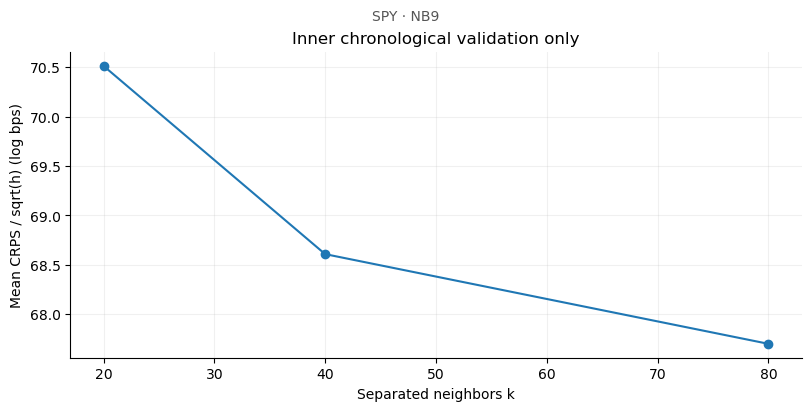

In [20]:
tuning=[]
for k in K_GRID:
    for t in inner_queries:
        ids,w,d=neighbors(Q_inner,t,k)
        losses=[crps(targets[ids,j],w,targets[t,j])/np.sqrt(h) for j,h in enumerate(HORIZONS)]
        tuning.append(dict(k=k,date=index[t],normalized_crps=float(np.mean(losses))))
tuning=pd.DataFrame(tuning);selection=tuning.groupby('k').normalized_crps.agg(['mean','count']).reset_index()
assert selection['count'].nunique()==1
K=int(selection.loc[selection['mean'].idxmin(),'k'])
# Support threshold fitted wholly inside calibration using the final, frozen metric.
support_radii=np.array([neighbors(Q,t,K)[2][-1] for t in inner_queries])
support_threshold=float(np.quantile(support_radii,SUPPORT_QUANTILE))
print('Selected k:',K,'; calibration 95th-percentile neighbor radius:',support_threshold)
if K in (min(K_GRID),max(K_GRID)):
    print('Boundary selection: best among this finite grid; a global optimum is not established. Do not expand the grid after inspecting later scores.')
display(selection.assign(mean_crps_bps=selection['mean']*1e4)[['k','mean_crps_bps','count']])
fig,ax=plt.subplots(figsize=(8,4),layout='constrained');ax.plot(selection.k,selection['mean']*1e4,'o-')
ax.set(xlabel='Separated neighbors k',ylabel='Mean CRPS / sqrt(h) (log bps)',title='Inner chronological validation only')
finish(fig,'01_neighbor_selection.png')

## 4. Later expanding-library forecasts and honest baselines
Issue a forecast every later session for which all five evaluation targets are known. Each forecast's library includes newly matured earlier later-period observations; this is an expanding forecast-origin protocol, not a single frozen training set. Scales and settings remain frozen.

Compare the analog distribution with (i) all eligible historical outcomes and (ii) the most recent 250 eligible outcomes, both equally weighted. Baselines share the same maximum-horizon label-maturity and query exclusion rules; baseline observations are not thinned. They are operational competitors, not matched effective-sample-size controls. Zero return is a separate point-only baseline.

Flag analog radii above their calibration 95th percentile, or effective weight counts below $k/4$, as unsupported. Keep these forecasts in the primary score so abstention cannot hide failures; report support-qualified results separately. The threshold is a diagnostic heuristic and may be optimistic because scaling and neighbor count use calibration data. An empty support-qualified subset remains empty.

,model,horizon,n,RMSE_bps,CRPS_bps,Brier,coverage80
0,analog,1,654,99.6066,48.9857,0.2530,0.8058
1,analog,2,654,135.3415,68.1087,0.2440,0.8257
2,analog,3,654,166.4597,83.9726,0.2448,0.8180
3,analog,4,654,187.0674,94.8045,0.2414,0.8119
4,analog,5,654,203.1863,105.4972,0.2455,0.8180
5,historical,1,654,98.7357,49.4008,0.2465,0.8746
6,historical,2,654,134.1595,69.5767,0.2437,0.8731
7,historical,3,654,165.0759,85.7346,0.2402,0.8777
8,historical,4,654,185.8753,97.4904,0.2377,0.8578
9,historical,5,654,201.7967,108.5074,0.2390,0.8624


,horizon,n,RMSE_bps,MAE_bps
0,1,654,98.959,66.294
1,2,654,134.817,95.467
2,3,654,166.282,118.663
3,4,654,187.771,134.438
4,5,654,204.479,151.977


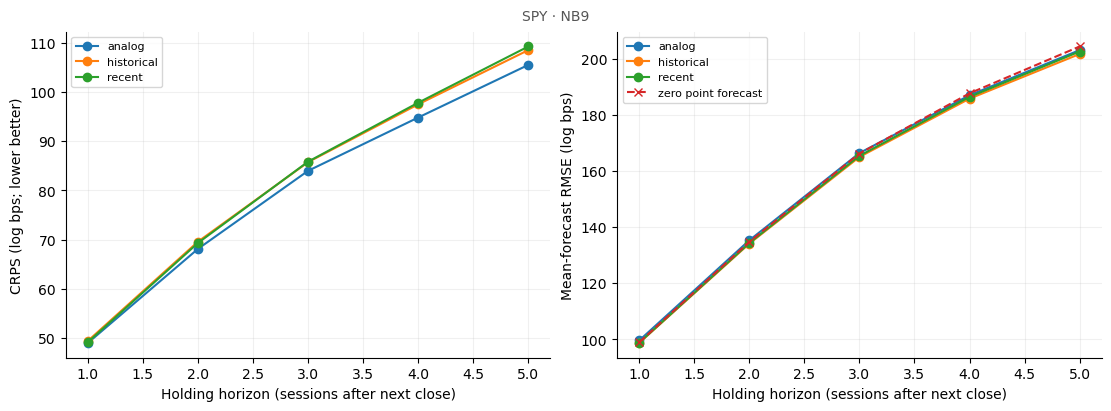

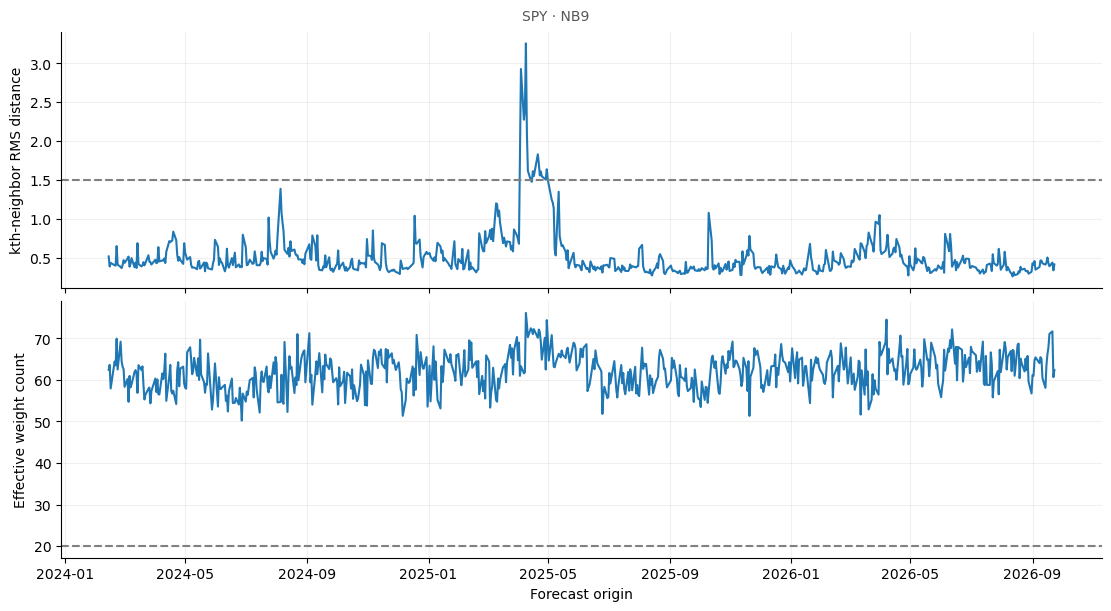

In [22]:
records=[];support_rows=[];audit=[]
for t in later_queries:
    ids,w,d=neighbors(Q,t,K);all_ids=eligible_ids(t);recent=all_ids[-RECENT_COUNT:]
    neff=1/(w@w);supported=bool(d[-1]<=support_threshold and neff>=K/4)
    support_rows.append(dict(date=index[t],query=int(t),radius=d[-1],neff=neff,supported=supported,library_size=len(all_ids)))
    audit.append(dict(query_date=index[t],latest_neighbor_signal=index[ids.max()],
        latest_neighbor_label_end=market.index[int(label_ends[ids,-1].max())],min_signal_separation=int(np.diff(np.sort(positions[ids])).min())))
    samples={'analog':(ids,w),'historical':(all_ids,np.full(len(all_ids),1/len(all_ids))),
             'recent':(recent,np.full(len(recent),1/len(recent)))}
    for model,(ii,ww) in samples.items():
        for j,h in enumerate(HORIZONS):
            records.append(dict(date=index[t],label_end=market.index[int(label_ends[t,j])],horizon=int(h),model=model,
                actual=float(targets[t,j]),supported=supported,**score_distribution(targets[ii,j],ww,targets[t,j])))
forecasts=pd.DataFrame(records);support=pd.DataFrame(support_rows);audit=pd.DataFrame(audit)
def aggregate(f):
    s=f.groupby(['model','horizon']).agg(n=('actual','size'),mse=('squared_error','mean'),MAE=('absolute_error','mean'),
        CRPS=('crps','mean'),Brier=('brier','mean'),coverage80=('covered','mean'),width80=('width','mean')).reset_index()
    s['RMSE_bps']=np.sqrt(s.mse)*1e4
    for col in ['MAE','CRPS','width80']:s[col+'_bps']=s[col]*1e4
    return s
scores=aggregate(forecasts);supported_scores=aggregate(forecasts[forecasts.supported])
zero_scores=pd.DataFrame([dict(horizon=int(h),n=len(later_queries),RMSE_bps=np.sqrt(np.mean(targets[later_queries,j]**2))*1e4,
                              MAE_bps=np.mean(abs(targets[later_queries,j]))*1e4) for j,h in enumerate(HORIZONS)])
display(scores[['model','horizon','n','RMSE_bps','CRPS_bps','Brier','coverage80']].round(4));display(zero_scores.round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for model,g in scores.groupby('model'):
    axes[0].plot(g.horizon,g.CRPS_bps,'o-',label=model);axes[1].plot(g.horizon,g.RMSE_bps,'o-',label=model)
axes[1].plot(zero_scores.horizon,zero_scores.RMSE_bps,'x--',label='zero point forecast')
for ax in axes:ax.set_xlabel('Holding horizon (sessions after next close)');ax.legend(fontsize=8)
axes[0].set_ylabel('CRPS (log bps; lower better)');axes[1].set_ylabel('Mean-forecast RMSE (log bps)')
finish(fig,'02_forecast_scores.png')
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True,layout='constrained')
axes[0].plot(support.date,support.radius);axes[0].axhline(support_threshold,color='gray',ls='--');axes[0].set_ylabel('kth-neighbor RMS distance')
axes[1].plot(support.date,support.neff);axes[1].axhline(K/4,color='gray',ls='--');axes[1].set(ylabel='Effective weight count',xlabel='Forecast origin')
finish(fig,'03_forecast_support.png')

## 5. Distribution calibration and conditional performance
An 80% empirical interval should cover approximately 80% of outcomes under appropriate calibration, but finite analog samples and dependence affect that comparison. Plot coverage and interval width together. For directional calibration, bin predicted positive-return probabilities into five fixed-width bins; show bins with at least 20 forecasts and retain all counts in exports. Sparse bins are not evidence of calibration.

The midpoint PIT is $F(y^-)+\tfrac12P(Y=y)$; uniformity is an ideal continuous-forecast reference, not a formal test for these discrete dependent forecasts. Use a 63-origin rolling mean CRPS difference to examine time variation without choosing a favorable subperiod.

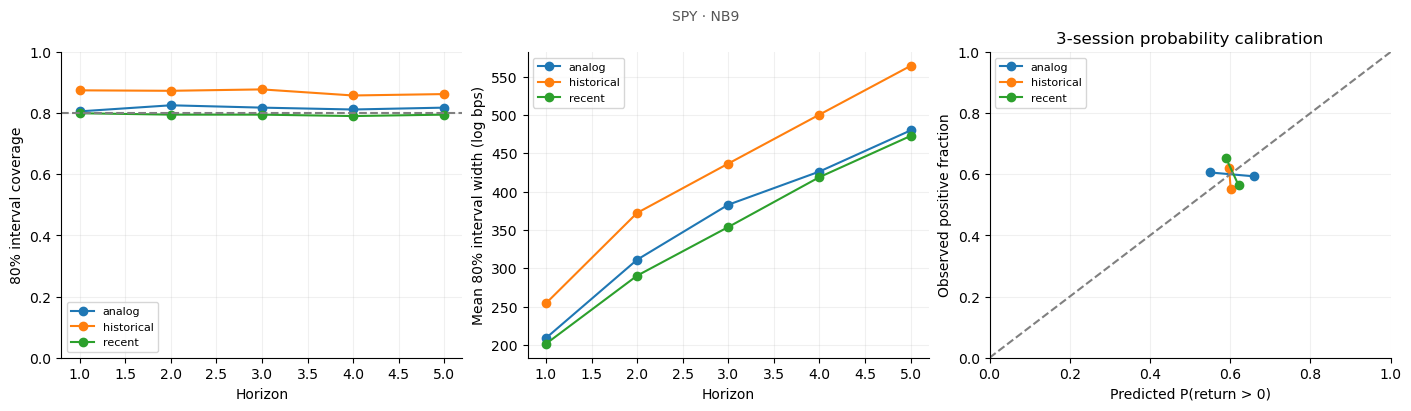

/var/folders/kf/_m2km__d5bb0zspsmwn5gvdh0000gn/T/ipykernel_1751/785796074.py:110: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.savefig(OUT/name,dpi=145,bbox_inches="tight");plt.show()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


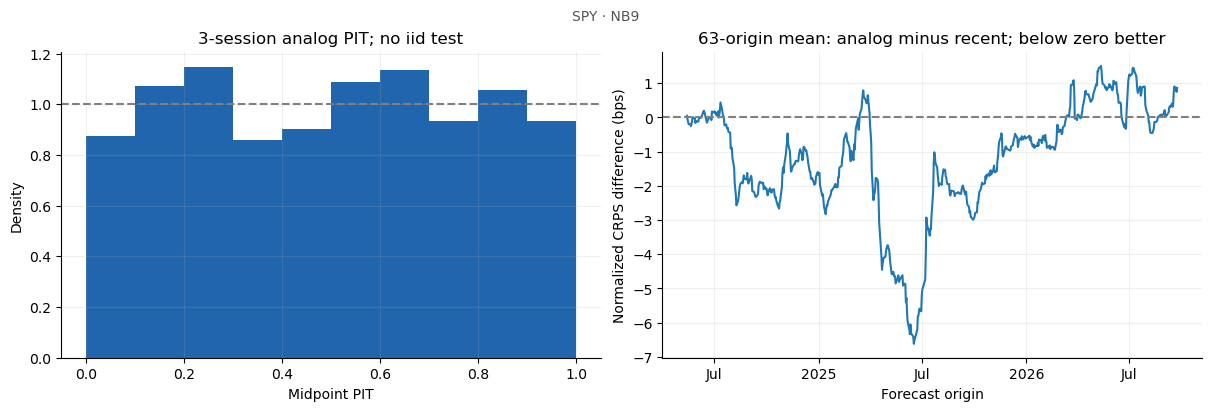

In [24]:
reliability=[]
for (model,h),g in forecasts.groupby(['model','horizon']):
    bin_id=np.minimum((g.p_up.to_numpy()*5).astype(int),4)
    for b in range(5):
        part=g.iloc[np.flatnonzero(bin_id==b)]
        reliability.append(dict(model=model,horizon=h,bin=b,n=len(part),mean_probability=part.p_up.mean(),observed_fraction=(part.actual>0).mean()))
reliability=pd.DataFrame(reliability)
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for model,g in scores.groupby('model'):
    axes[0].plot(g.horizon,g.coverage80,'o-',label=model);axes[1].plot(g.horizon,g.width80_bps,'o-',label=model)
    r=reliability[(reliability.model==model)&(reliability.horizon==3)&(reliability.n>=20)]
    axes[2].plot(r.mean_probability,r.observed_fraction,'o-',label=model)
axes[0].axhline(.8,color='gray',ls='--');axes[0].set(xlabel='Horizon',ylabel='80% interval coverage',ylim=(0,1))
axes[1].set(xlabel='Horizon',ylabel='Mean 80% interval width (log bps)')
axes[2].plot([0,1],[0,1],'--',color='gray');axes[2].set(xlabel='Predicted P(return > 0)',ylabel='Observed positive fraction',title='3-session probability calibration',xlim=(0,1),ylim=(0,1))
for ax in axes:ax.legend(fontsize=8)
finish(fig,'04_distribution_calibration.png')
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
a=forecasts[(forecasts.model=='analog')&(forecasts.horizon==3)]
axes[0].hist(a.pit,bins=np.linspace(0,1,11),density=True,color='#2166ac');axes[0].axhline(1,color='gray',ls='--')
axes[0].set(xlabel='Midpoint PIT',ylabel='Density',title='3-session analog PIT; no iid test')
paired=forecasts.pivot(index=['date','horizon'],columns='model',values='crps')
rolling_difference=(paired.analog-paired.recent).unstack('horizon').div(np.sqrt(HORIZONS),axis=1).mean(axis=1)
axes[1].plot(rolling_difference.index,rolling_difference.rolling(63).mean()*1e4);axes[1].axhline(0,color='gray',ls='--')
axes[1].set(xlabel='Forecast origin',ylabel='Normalized CRPS difference (bps)',title='63-origin mean: analog minus recent; below zero better')
import matplotlib.dates as mdates
locator=mdates.AutoDateLocator(minticks=3,maxticks=5)
axes[1].xaxis.set_major_locator(locator);axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
finish(fig,'05_pit_time_variation.png')

## 6. Paired block-resampling uncertainty and a random-label reference
For each horizon and the predeclared normalized aggregate, resample paired origin-level CRPS differences in 20-origin moving blocks. Preserve alignment across models and horizons. The 2.5–97.5% bootstrap range approximates uncertainty under local dependence assumptions; it does not account for earlier research choices or arbitrary nonstationarity. It is not an iid significance test or a multiplicity-adjusted claim across horizons.

A second exploratory reference replaces analog outcomes with randomly chosen eligible historical outcome vectors at every fifth later origin, keeping the observed analog weights. Sampling is without replacement; all five horizons remain paired within each chosen outcome vector. This isolates state-to-outcome matching conditional on weights, but it does not preserve neighbor spacing, label overlap structure or volatility clustering. It is a limited placebo, not a full financial null or a p-value.

,target,difference_bps,low_bps,high_bps
0,h=1,-0.172,-0.935,0.523
1,h=2,-1.200,-2.915,0.187
2,h=3,-1.862,-4.031,-0.220
3,h=4,-3.010,-5.693,-0.832
4,h=5,-3.746,-7.033,-1.070
5,normalized aggregate,-1.055,-2.174,-0.206


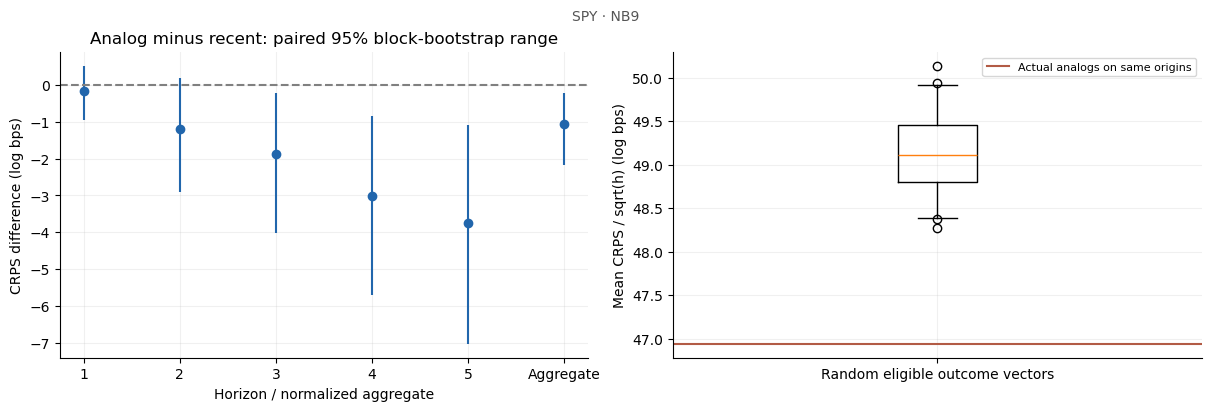

In [26]:
differences=(paired.analog-paired.recent).unstack('horizon').to_numpy()
rng=np.random.default_rng(SEED+1);replicate_means=[]
for b in range(BOOT_REPS):
    starts=rng.integers(0,len(differences)-BLOCK_LENGTH+1,int(np.ceil(len(differences)/BLOCK_LENGTH)))
    ids=np.concatenate([np.arange(s,s+BLOCK_LENGTH) for s in starts])[:len(differences)]
    means=differences[ids].mean(axis=0);replicate_means.append(np.r_[means,np.mean(means/np.sqrt(HORIZONS))])
replicate_means=np.asarray(replicate_means)
point=np.r_[differences.mean(axis=0),np.mean(differences.mean(axis=0)/np.sqrt(HORIZONS))]
uncertainty=pd.DataFrame({'target':[f'h={h}' for h in HORIZONS]+['normalized aggregate'],
 'difference_bps':point*1e4,'low_bps':np.quantile(replicate_means,.025,axis=0)*1e4,'high_bps':np.quantile(replicate_means,.975,axis=0)*1e4})
display(uncertainty.round(3))
rng=np.random.default_rng(SEED+2);placebo=[];placebo_queries=later_queries[::5];observed_placebo=[]
cache=[]
for t in placebo_queries:
    ids,w,d=neighbors(Q,t,K);pool=eligible_ids(t);cache.append((t,ids,w,pool))
    observed_placebo.append(np.mean([crps(targets[ids,j],w,targets[t,j])/np.sqrt(h) for j,h in enumerate(HORIZONS)]))
for rep in range(PLACEBO_REPS):
    losses=[]
    for t,ids,w,pool in cache:
        random_ids=rng.choice(pool,K,replace=False)
        assert (label_ends[random_ids,-1]<=positions[t]).all()
        losses.append(np.mean([crps(targets[random_ids,j],w,targets[t,j])/np.sqrt(h) for j,h in enumerate(HORIZONS)]))
    placebo.append(dict(replicate=rep,normalized_CRPS=float(np.mean(losses))))
placebo=pd.DataFrame(placebo)
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].vlines(np.arange(len(point)),uncertainty.low_bps,uncertainty.high_bps,color='#2166ac')
axes[0].plot(np.arange(len(point)),uncertainty.difference_bps,'o',color='#2166ac')
axes[0].axhline(0,color='gray',ls='--');axes[0].set(xticks=np.arange(len(point)),xticklabels=[str(h) for h in HORIZONS]+['Aggregate'],xlabel='Horizon / normalized aggregate',ylabel='CRPS difference (log bps)',title='Analog minus recent: paired 95% block-bootstrap range')
axes[1].boxplot(placebo.normalized_CRPS*1e4,whis=(5,95));axes[1].axhline(np.mean(observed_placebo)*1e4,color='#b25b45',label='Actual analogs on same origins')
axes[1].set(xticks=[1],xticklabels=['Random eligible outcome vectors'],ylabel='Mean CRPS / sqrt(h) (log bps)');axes[1].legend(fontsize=8)
finish(fig,'06_uncertainty_placebo.png')

## 7. Latest snapshot forecast and historical analog audit
Use exactly the selected model and all outcomes matured by the final snapshot close. Display weighted empirical 10–90% outcome ranges, mean forecasts and positive-return probabilities. These are forecast distributions, not confidence intervals for their means. They are not calibrated win probabilities or a trade instruction; evaluate the preceding coverage and loss results first.

A latest forecast outside the calibration support threshold is explicitly flagged. The neighbor catalog contains signal dates, last label-maturity dates, distances and weights, so every analog is inspectable. The entry close for this forecast occurs **after** the last observed close and is not yet known.

,as_of,horizon,supported,mean_bps,q10_bps,q90_bps,p_up
0,2026-10-01,1,True,-5.267,-145.345,120.193,0.561
1,2026-10-01,2,True,5.292,-168.970,145.011,0.498
2,2026-10-01,3,True,12.506,-251.618,196.014,0.632
3,2026-10-01,4,True,9.491,-220.936,187.623,0.522
4,2026-10-01,5,True,28.280,-233.781,239.302,0.616


,neighbor_date,last_label_end,distance,weight
0,2026-01-23,2026-02-02,0.141328,0.030978
1,2025-12-15,2025-12-23,0.155399,0.028048
2,2019-09-26,2019-10-04,0.160216,0.027110
3,2021-09-24,2021-10-04,0.167904,0.025677
4,2023-08-11,2023-08-21,0.176607,0.024147
5,2026-02-19,2026-02-27,0.181735,0.023288
6,2024-07-29,2024-08-06,0.191404,0.021751
7,2026-07-24,2026-08-03,0.192108,0.021643
8,2023-09-08,2023-09-18,0.203202,0.020013
9,2023-05-15,2023-05-23,0.204937,0.019769


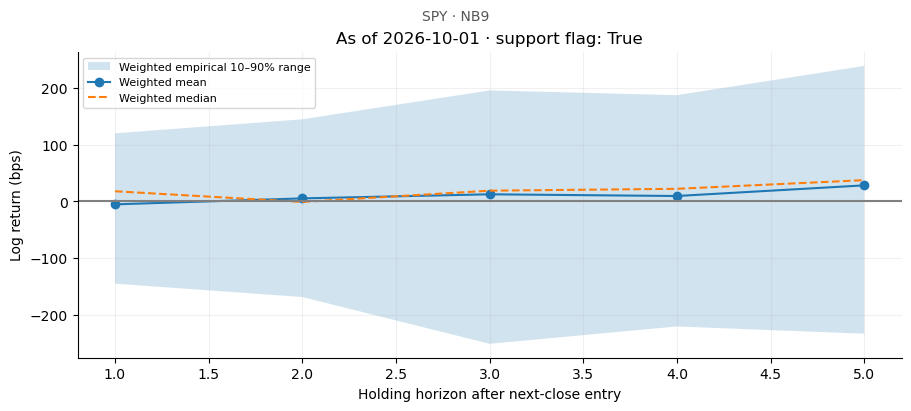

In [28]:
latest_t=len(index)-1;ids,w,d=neighbors(Q,latest_t,K);latest=[]
latest_supported=bool(d[-1]<=support_threshold and 1/(w@w)>=K/4)
for j,h in enumerate(HORIZONS):
    latest.append(dict(as_of=index[latest_t],horizon=int(h),supported=latest_supported,
        **describe(targets[ids,j],w)))
latest=pd.DataFrame(latest)
catalog=pd.DataFrame({'neighbor_date':index[ids],'last_label_end':[market.index[int(p)] for p in label_ends[ids,-1]],'distance':d,'weight':w})
assert (pd.to_datetime(catalog.last_label_end)<=index[latest_t]).all()
display(latest.assign(mean_bps=latest['mean']*1e4,q10_bps=latest.q10*1e4,q90_bps=latest.q90*1e4)[['as_of','horizon','supported','mean_bps','q10_bps','q90_bps','p_up']].round(3))
display(catalog.head(10))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.fill_between(latest.horizon,latest.q10*1e4,latest.q90*1e4,alpha=.2,label='Weighted empirical 10–90% range')
ax.plot(latest.horizon,latest['mean']*1e4,'o-',label='Weighted mean');ax.plot(latest.horizon,latest['median']*1e4,'--',label='Weighted median')
ax.axhline(0,color='gray');ax.set(xlabel='Holding horizon after next-close entry',ylabel='Log return (bps)',title=f'As of {index[-1].date()} · support flag: {latest_supported}');ax.legend(fontsize=8)
finish(fig,'07_latest_forecast.png')

## 8. Causality audit, computed conclusions and NB10 handoff
The audit verifies temporal eligibility, separated analog labels, immature forecast outcomes, reproducible scoring and frozen-prefix predictions. Historical scores include every scheduled mature origin, with no retrospective support-based removal from the primary comparison.

The state-space choices themselves were motivated by earlier work on this dataset. Even a favorable loss difference would require a new locked prospective period and checks across assets before practical use. NB10 can evaluate decisions, but a trading layer should not manufacture confidence from a forecasting model that fails these baselines.

In [30]:
t=int(later_queries[len(later_queries)//2]);ii,ww,dd=neighbors(Q,t,K)
pi,pw,pdists=neighbors(Q[:t+1],t,K)
assert np.array_equal(ii,pi) and np.allclose(ww,pw) and np.allclose(dd,pdists)
assert (label_ends[ii,-1]<=positions[t]).all()
# Poison unavailable targets: forecasts must be unchanged because only matured indices are used.
poisoned=targets.copy();poisoned[label_ends[:,-1]>positions[t]]=1e6
for j in range(MAX_H):assert describe(poisoned[ii,j],ww)==describe(targets[ii,j],ww)
assert not forecasts[['mean','crps','brier']].isna().any().any()
assert (forecasts.crps>=-1e-12).all() and forecasts.p_up.between(0,1).all()
assert forecasts.groupby(['model','horizon']).size().nunique()==1
exports={'inner_validation':tuning,'neighbor_selection':selection,'forecasts':forecasts,'forecast_scores':scores,
 'supported_scores':supported_scores,'zero_point_scores':zero_scores,'support_diagnostics':support,'neighbor_time_audit':audit,
 'probability_reliability':reliability,'paired_block_uncertainty':uncertainty,'random_label_reference':placebo,
 'latest_forecast':latest,'latest_neighbors':catalog}
for name,f in exports.items():f.to_csv(OUT/(name+'.csv'),index=False)
model=dict(features=FEATURES,center=final_center.tolist(),scale=final_scale.tolist(),inner_center=inner_center.tolist(),
 inner_scale=inner_scale.tolist(),k=K,weight_theta=WEIGHT_THETA,theiler=THEILER,neighbor_spacing=THIN,
 support_radius=support_threshold,minimum_neff=K/4,entry_delay_sessions=1,horizons=HORIZONS.tolist(),
 library_protocol='Expanding; all selected labels mature through forecast origin; query exclusion applied')
(OUT/'forecast_configuration.json').write_text(json.dumps(model,indent=2))
manifest=dict(notebook='9 — Short-horizon analog forecasting',source=source['provenance'],input_hashes=source_hashes,
 calibration_end=str(cut.date()),inner_scale_end=str(index[initial-1].date()),versions=versions,
 config=dict(seed=SEED,k_grid=K_GRID,k_selected=K,inner_fraction=INNER_FRACTION,inner_step=INNER_STEP,
 recent_count=RECENT_COUNT,block_length=BLOCK_LENGTH,bootstrap_replicates=BOOT_REPS,placebo_replicates=PLACEBO_REPS,
 support_quantile=SUPPORT_QUANTILE),executed_utc=datetime.now(timezone.utc).isoformat(),checks='passed',
 claims='Chronological exploratory forecast evaluation; previously examined later period, no trading-skill claim')
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
display(Markdown(f'**Selected k={K}.** {len(inner_queries)} inner validation origins; {len(later_queries)} later evaluated origins at each horizon.'))
display(Markdown(f'**Support:** {support.supported.mean():.1%} of later forecasts pass the calibration support rule; primary scores retain all origins.'))
row=uncertainty.iloc[-1]
display(Markdown(f'**Analog minus recent normalized CRPS:** {row.difference_bps:.3f} bps, paired block-bootstrap range [{row.low_bps:.3f}, {row.high_bps:.3f}]. Negative favors analogs.'))
display(Markdown(f'**Latest snapshot:** {index[-1].date()}, supported={latest_supported}. No current-market claim is implied.'))
print('Passed CRPS, target indexing, label maturity, temporal separation, common origins, prefix and poisoned-future checks.')
print('Exported',len(exports),'tables, 7 figures and forecast configuration.')

**Selected k=80.** 106 inner validation origins; 654 later evaluated origins at each horizon.

**Support:** 97.2% of later forecasts pass the calibration support rule; primary scores retain all origins.

**Analog minus recent normalized CRPS:** -1.055 bps, paired block-bootstrap range [-2.174, -0.206]. Negative favors analogs.

**Latest snapshot:** 2026-10-01, supported=True. No current-market claim is implied.

Passed CRPS, target indexing, label maturity, temporal separation, common origins, prefix and poisoned-future checks.
Exported 13 tables, 7 figures and forecast configuration.


## References
- [Hyndman & Athanasopoulos, Forecasting: Principles and Practice — time-series cross-validation](https://otexts.com/fpp3/tscv.html): rolling forecast origins and horizon-specific evaluation.
- [Gneiting & Raftery (2007), Strictly Proper Scoring Rules, Prediction, and Estimation](https://doi.org/10.1198/016214506000001437): proper probabilistic forecast evaluation. The empirical CRPS formula is explicitly implemented and checked above.

**Next: NB10 — Trading decision layer.** Retain forecast uncertainty, baseline comparisons and support flags; add execution conventions, costs, position sizing and risk rather than treating a positive conditional mean as sufficient evidence for a trade.